# TiO2 model training and evaluation
Stage C uses the saved model and metrics. It does not retrain during the demonstration. Validation is preliminary: exact input groups are separated, but independent study IDs are unavailable. Outputs are in reported mlogk units, not removal percentages.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.predict import TiO2Predictor
card = json.loads((ROOT / 'models/model_card.json').read_text())
print('Selected model:', card['model_name'])
print('Training rows:', card['train_rows'], '| held out rows:', card['test_rows'])
print('Numerical prototype enabled:', card['enabled_for_prototype'])
pd.read_csv(ROOT / 'outputs/model_comparison_cv.csv')[['model', 'cv_mae_mean', 'cv_mae_std', 'best_parameters']]

Selected model: Random Forest
Training rows: 350 | held out rows: 90
Numerical prototype enabled: True


,model,cv_mae_mean,cv_mae_std,best_parameters
0,Random Forest,0.159412,0.024410,"{""model__max_depth"": null, ""model__min_samples..."
1,Ridge,0.191479,0.022930,"{""model__alpha"": 0.1}"
2,Dummy median,0.416742,0.051242,{}


## Untouched final test results
The model was selected using training CV before evaluating these test outcomes. R squared is not percent accuracy. MAE is in the reported transformed target.

In [2]:
pd.DataFrame({'Selected model': card['test_metrics'], 'Median baseline': card['baseline_test_metrics']}).T

,n,mae,rmse,r2
Selected model,90.0,0.145859,0.212763,0.873081
Median baseline,90.0,0.440148,0.597393,-0.000589


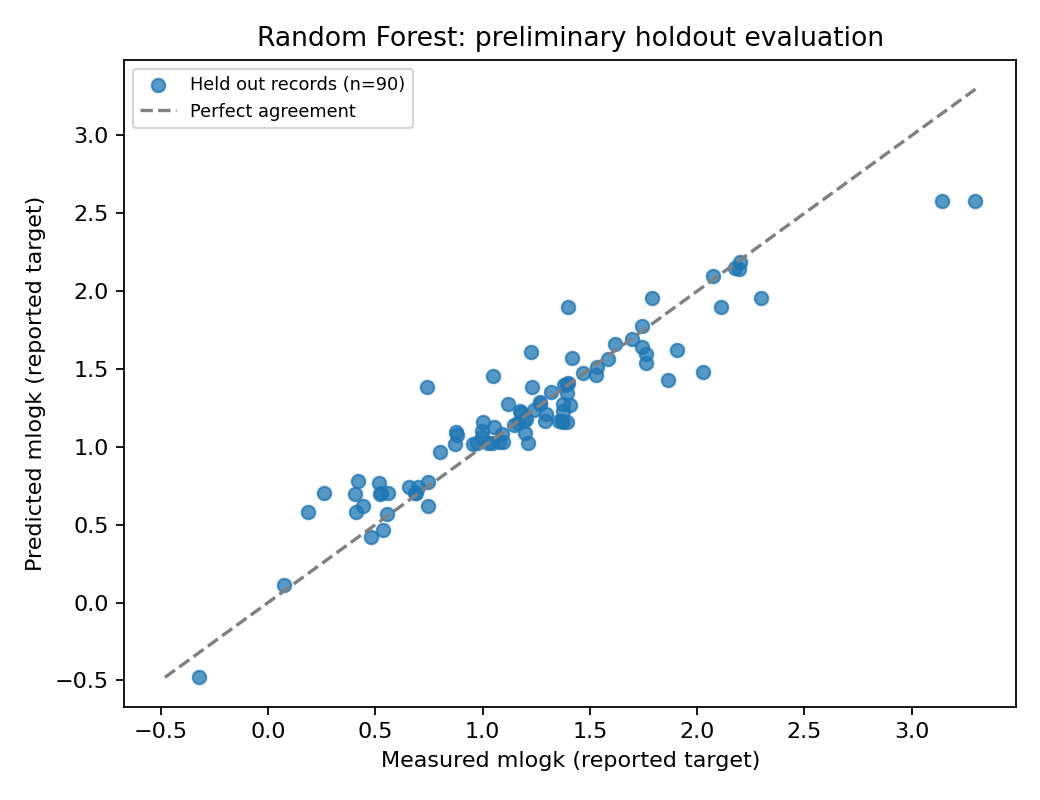

In [3]:
display(Image(filename=str(ROOT / 'outputs/predicted_vs_measured.png')))

In [4]:
print('Held out rows passing domain policy:', card['eligible_test_rows'], '/', card['test_rows'])
print('Eligible subset metrics:', card['eligible_test_metrics'])
print('This subset is not a calibrated confidence region.')

Held out rows passing domain policy: 38 / 90
Eligible subset metrics: {'n': 38, 'mae': 0.10235815075757548, 'rmse': 0.1539438721183134, 'r2': 0.9028594677360161}
This subset is not a calibrated confidence region.


## Run one numerical prediction
Use the first eligible held out SMX condition where available, selected by inputs rather than prediction error. This is a published test observation, not a new lab experiment. The default command line example separately uses a training condition and labels it explicitly.

In [5]:
demo_file = ROOT / 'config/demo_holdout_scenario.json'
if not demo_file.exists(): demo_file = ROOT / 'config/demo_ml_scenario.json'
scenario = json.loads(demo_file.read_text())
predictor = TiO2Predictor()
answer = predictor.predict(scenario)
print('Scenario:', scenario)
print({k: answer[k] for k in ['status', 'prediction', 'prediction_target', 'exact_training_conditions', 'reasons']})
test_predictions = pd.read_csv(ROOT / 'outputs/test_predictions.csv')
test_predictions.loc[test_predictions.source_row.eq(scenario['source_row']), ['Molecule_Name', 'mlogk', 'predicted_mlogk']]

Scenario: {'material_id': 'M02', 'profile_id': 'dataset_unspecified_tio2', 'pollutant_id': 'Sulfamethoxazole', 'light_type': 'UV', 'water_matrix': 'laboratory_solution', 'requested_endpoint': 'mlogk', 'light_intensity_mW_cm2': 1.51, 'temperature_C': 25.0, 'dose_g_L': 0.1, 'concentration_mg_L': 24.82, 'pH': 3.0, 'demo_note': 'First eligible sulfamethoxazole holdout row, otherwise first eligible holdout row; chosen by inputs, not smallest prediction error.', 'source_row': 256}
{'status': 'experimental_ml_prediction', 'prediction': 1.2776774999999987, 'prediction_target': 'mlogk', 'exact_training_conditions': False, 'reasons': []}


,Molecule_Name,mlogk,predicted_mlogk
50,Sulfamethoxazole,1.2676,1.277677


## Check an unsupported request
Methylene blue is absent from this training dataset. The API must return evidence only rather than fabricate a numerical prediction.

In [6]:
unsupported = dict(scenario, pollutant_id='methylene_blue')
fallback = predictor.predict(unsupported)
print({k: fallback[k] for k in ['status', 'prediction', 'reasons']})

{'status': 'evidence_only', 'prediction': None, 'reasons': ['Pollutant is absent from the model training categories.']}


## Limits and next stage
No independent study or lab validation. Phase, size, surface area, wavelength and matrix effects are unmodelled. No prediction interval is claimed and no inverse log conversion is made. Next: integrate the saved model with deterministic evidence screening and recommendation rules for all 15 families.